$\text{Extracting the data from the CSV files from the JPL NASA Horizons application}$

In [2]:
import numpy as np
import pandas as pd

# Define column names for this Horizons file
column_names = [
    'JDTDB', 'Calendar_Date',
    'X', 'Y', 'Z',
    'VX', 'VY', 'VZ'
]

# Read the file and extract only the ephemeris data
data_lines = []

with open("/home/suparnajit2005/GitHub/Classical_mechanics_simulations/Central-force-motion/Data/NASA/horizons_results_mercury.csv", "r") as f:

    in_data_zone = False

    for line in f:

        if "$$EOE" in line:
            break

        if "$$SOE" in line:
            in_data_zone = True
            continue

        if in_data_zone:

            cleaned_line = line.strip().rstrip(',')

            if cleaned_line:
                row = [value.strip() for value in cleaned_line.split(',')]
                data_lines.append(row)


# Construct DataFrame
df = pd.DataFrame(data_lines, columns=column_names)

# Convert columns to appropriate data types
numeric_cols = [
    'JDTDB', 'X', 'Y', 'Z',
    'VX', 'VY', 'VZ'
]

df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric)

# Preview dataset
print(df.head(62))


# Convert DataFrame into NumPy array
Data_matrix = df.to_numpy()


# -----------------------------
# Time Initialisation
# -----------------------------

t0 = np.ones_like(Data_matrix.T[0], dtype=float) * np.min(Data_matrix.T[0])

t_days = Data_matrix.T[0].astype(float) - t0


# -----------------------------
# State Initialisation
# -----------------------------

JPL_data = np.array([
    Data_matrix.T[2].astype(float),  # X
    Data_matrix.T[3].astype(float),  # Y
    Data_matrix.T[4].astype(float),  # Z
    Data_matrix.T[5].astype(float),  # VX
    Data_matrix.T[6].astype(float),  # VY
    Data_matrix.T[7].astype(float)   # VZ
])

print("Time shape:", t_days.shape)
print("State shape:", JPL_data.shape)
print("Initial position:", JPL_data[:3, 0])
print("Initial velocity:", JPL_data[3:, 0])


        JDTDB                   Calendar_Date             X             Y  \
0   2461343.5  A.D. 2026-Oct-30 00:00:00.0000  5.005945e+07  9.740920e+06   
1   2461344.5  A.D. 2026-Oct-31 00:00:00.0000  4.826087e+07  1.346185e+07   
2   2461345.5  A.D. 2026-Nov-01 00:00:00.0000  4.609045e+07  1.707378e+07   
3   2461346.5  A.D. 2026-Nov-02 00:00:00.0000  4.354875e+07  2.054277e+07   
4   2461347.5  A.D. 2026-Nov-03 00:00:00.0000  4.064104e+07  2.383361e+07   
..        ...                             ...           ...           ...   
57  2461400.5  A.D. 2026-Dec-26 00:00:00.0000 -9.939735e+06 -6.201107e+07   
58  2461401.5  A.D. 2026-Dec-27 00:00:00.0000 -6.603849e+06 -6.213655e+07   
59  2461402.5  A.D. 2026-Dec-28 00:00:00.0000 -3.248948e+06 -6.208198e+07   
60  2461403.5  A.D. 2026-Dec-29 00:00:00.0000  1.151913e+05 -6.184651e+07   
61  2461404.5  A.D. 2026-Dec-30 00:00:00.0000  3.478653e+06 -6.142947e+07   

               Z         VX         VY         VZ  
0   8.434890e+04 -18.67

In [3]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


#This class contains the initial position and velocity of the celestial body:

class body:
    def __init__(self,name,mass,pos,vel):
        self.name=name
        self.mass=mass
        self.pos=np.array(pos,dtype=float)
        self.vel=np.array(vel,dtype=float)
        
# Data from the NASA Horizons data :


b1 = body("Sun", 1988410e24, np.array([-1.602325979919614E+05,-7.005062866580029E+05 , -2.888835766883729E+05]), np.array([1.031902521729396E-02, 4.449029074274385E-03, 1.684369200411074E-03]))

b2 = body("Mercury", 3.302e23, np.array([5.005945338170964E+07, 9.740919593283530E+06, 8.434890081924666E+04]), np.array([-1.867497438964642E+01, 4.357107773137023E+01, 2.521169409511218E+01]))

b3 = body("Venus", 48.685e23, np.array([8.302432525358570E+07,6.425708656179664E+07 , 2.367777884417082E+07]), np.array([-2.247968325249581E+01,  2.391654264351647E+01,  1.218439937840489E+01]))

b4 = body("Earth", 5.97219e24, np.array([1.197286311109774E+08,  7.982463976381977E+07,  3.461601209038475E+07]), np.array([-1.805688133808997E+01,  2.195386395433621E+01,  9.517041959974549E+00]))

b5 = body("Mars", 6.4171e23, np.array([-3.932279784924307E+07,  2.124476993615854E+08,  9.853347780953923E+07]), np.array([-2.297156296757593E+01, -1.971991104355783E+00, -2.850371983145413E-01]))

b6 = body("Jupiter",18.9819e26 , np.array([ -5.469428826456959E+08,  5.251793803450833E+08,  2.384273303310489E+08]), np.array([-9.636786632066425E+00, -7.784841955694026E+00, -3.102163240189204E+00]))


bodies=[b1,b2,b3,b4,b5,b6]


N=len(bodies)

def acc(mass,pos):

    
    a=np.zeros((len(bodies),3))

    for i in range(len(bodies)):
        for j  in range(len(bodies)):

            
            if i!=j:
                G = 6.67430e-20
                
                r=pos[i]-pos[j]

                ax=-((G*mass[j]*r[0])/(np.linalg.norm(r)**3))
                ay=-((G*mass[j]*r[1])/(np.linalg.norm(r)**3))
                az=-((G*mass[j]*r[2])/(np.linalg.norm(r)**3))

                a[i]+=np.array([ax,ay,az])

    return a
                

            
def eq_o_mot(t,state):
    N=len(bodies)
    pos=state[:3*N].reshape(N,3)
    vel=state[3*N:].reshape(N,3)

    m=np.array([])
    for i in range(N):
        m=np.append(m,bodies[i].mass)

    ac=acc(m,pos)

    return np.concatenate((vel.flatten(),ac.flatten()))


initial_pos=np.array([])
initial_vel=np.array([])

for i in range(N):
    initial_pos=np.append(initial_pos,bodies[i].pos)
    initial_vel=np.append(initial_vel,bodies[i].vel)

state0=np.concatenate((initial_pos,initial_vel))

days=62

t_eval = t_days * 24 * 3600

t_span = (t_eval[0], t_eval[-1])



# Position is in km and velocity is in km/s, so use separate absolute tolerances.
# For convergence checking, rerun with rtol=1e-11 and atol values 10x smaller.
# N is the number of bodies; each body has 3 position and 3 velocity components.
# The state vector stores all 3*N positions first, followed by all 3*N velocities.
# np.full(length, value) creates an array with `length` copies of `value`.
# Therefore each block needs 3*N tolerances; for 6 bodies, atol has 36 entries.


atol = np.concatenate((
    np.full(3 * N, 1e-6),  # positions: 1e-3 km = 1 m
    np.full(3 * N, 1e-10),  # velocities: 1e-9 km/s
))



sol=solve_ivp(
    eq_o_mot,
    t_span,
    state0,
    method='DOP853',
    t_eval=t_eval,
    rtol=1e-12,  # This part is generated by AI.
    atol=atol,
)



        

In [4]:
sol

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  8.640e+04 ...  5.184e+06  5.270e+06]
        y: [[-1.602e+05 -1.593e+05 ... -1.084e+05 -1.076e+05]
            [-7.005e+05 -7.001e+05 ... -6.752e+05 -6.747e+05]
            ...
            [-7.785e+00 -7.797e+00 ... -8.472e+00 -8.483e+00]
            [-3.102e+00 -3.108e+00 ... -3.416e+00 -3.421e+00]]
      sol: None
 t_events: None
 y_events: None
     nfev: 602
     njev: 0
      nlu: 0

In [5]:
Solution_matrix=pd.DataFrame(sol.y)
Solution_matrix

,0,1,2,3,4,5,6,7,8,9,...,52,53,54,55,56,57,58,59,60,61
0,-1.602326e+05,-1.593414e+05,-1.584509e+05,-1.575611e+05,-1.566720e+05,-1.557837e+05,-1.548961e+05,-1.540092e+05,-1.531231e+05,-1.522378e+05,...,-1.150881e+05,-1.142487e+05,-1.134106e+05,-1.125736e+05,-1.117379e+05,-1.109035e+05,-1.100703e+05,-1.092384e+05,-1.084078e+05,-1.075784e+05
1,-7.005063e+05,-7.001213e+05,-6.997351e+05,-6.993476e+05,-6.989590e+05,-6.985691e+05,-6.981779e+05,-6.977855e+05,-6.973918e+05,-6.969968e+05,...,-6.788066e+05,-6.783566e+05,-6.779054e+05,-6.774531e+05,-6.769996e+05,-6.765450e+05,-6.760892e+05,-6.756323e+05,-6.751743e+05,-6.747151e+05
2,-2.888836e+05,-2.887378e+05,-2.885915e+05,-2.884446e+05,-2.882972e+05,-2.881492e+05,-2.880007e+05,-2.878516e+05,-2.877020e+05,-2.875517e+05,...,-2.805440e+05,-2.803687e+05,-2.801928e+05,-2.800164e+05,-2.798395e+05,-2.796621e+05,-2.794841e+05,-2.793056e+05,-2.791266e+05,-2.789470e+05
3,5.005945e+07,4.826087e+07,4.609045e+07,4.354875e+07,4.064104e+07,3.737792e+07,3.377575e+07,2.985703e+07,2.565043e+07,2.119059e+07,...,-2.599858e+07,-2.290125e+07,-1.973726e+07,-1.651605e+07,-1.324710e+07,-9.939891e+06,-6.604012e+06,-3.249119e+06,1.150136e+05,3.478468e+06
4,9.740920e+06,1.346185e+07,1.707378e+07,2.054277e+07,2.383361e+07,2.691045e+07,2.973762e+07,3.228055e+07,3.450685e+07,3.638740e+07,...,-5.872726e+07,-5.973304e+07,-6.056607e+07,-6.122450e+07,-6.170666e+07,-6.201112e+07,-6.213659e+07,-6.208203e+07,-6.184655e+07,-6.142950e+07
5,8.434890e+04,2.258523e+06,4.413004e+06,6.529604e+06,8.588964e+06,1.057084e+07,1.245448e+07,1.421908e+07,1.584438e+07,1.731121e+07,...,-2.860784e+07,-2.946611e+07,-3.023900e+07,-3.092455e+07,-3.152089e+07,-3.202626e+07,-3.243899e+07,-3.275751e+07,-3.298035e+07,-3.310612e+07
6,8.302433e+07,8.104983e+07,7.901184e+07,7.691191e+07,7.475166e+07,7.253275e+07,7.025687e+07,6.792579e+07,6.554130e+07,6.310525e+07,...,-5.955100e+07,-6.205648e+07,-6.451254e+07,-6.691723e+07,-6.926862e+07,-7.156483e+07,-7.380403e+07,-7.598444e+07,-7.810431e+07,-8.016196e+07
7,6.425709e+07,6.629782e+07,6.828618e+07,7.022057e+07,7.209945e+07,7.392132e+07,7.568471e+07,7.738822e+07,7.903047e+07,8.061014e+07,...,7.952560e+07,7.789367e+07,7.619906e+07,7.444312e+07,7.262725e+07,7.075290e+07,6.882155e+07,6.683476e+07,6.479411e+07,6.270123e+07
8,2.367778e+07,2.472101e+07,2.574469e+07,2.674800e+07,2.773015e+07,2.869035e+07,2.962785e+07,3.054190e+07,3.143176e+07,3.229672e+07,...,3.956987e+07,3.899408e+07,3.838696e+07,3.774899e+07,3.708068e+07,3.638256e+07,3.565519e+07,3.489915e+07,3.411504e+07,3.330350e+07
9,1.197286e+08,1.181505e+08,1.165366e+08,1.148874e+08,1.132033e+08,1.114849e+08,1.097327e+08,1.079471e+08,1.061287e+08,1.042780e+08,...,3.173442e+06,5.597143e+05,-2.054224e+06,-4.667561e+06,-7.279484e+06,-9.889179e+06,-1.249583e+07,-1.509864e+07,-1.769678e+07,-2.028945e+07


In [6]:
Solution_matrix

,0,1,2,3,4,5,6,7,8,9,...,52,53,54,55,56,57,58,59,60,61
0,-1.602326e+05,-1.593414e+05,-1.584509e+05,-1.575611e+05,-1.566720e+05,-1.557837e+05,-1.548961e+05,-1.540092e+05,-1.531231e+05,-1.522378e+05,...,-1.150881e+05,-1.142487e+05,-1.134106e+05,-1.125736e+05,-1.117379e+05,-1.109035e+05,-1.100703e+05,-1.092384e+05,-1.084078e+05,-1.075784e+05
1,-7.005063e+05,-7.001213e+05,-6.997351e+05,-6.993476e+05,-6.989590e+05,-6.985691e+05,-6.981779e+05,-6.977855e+05,-6.973918e+05,-6.969968e+05,...,-6.788066e+05,-6.783566e+05,-6.779054e+05,-6.774531e+05,-6.769996e+05,-6.765450e+05,-6.760892e+05,-6.756323e+05,-6.751743e+05,-6.747151e+05
2,-2.888836e+05,-2.887378e+05,-2.885915e+05,-2.884446e+05,-2.882972e+05,-2.881492e+05,-2.880007e+05,-2.878516e+05,-2.877020e+05,-2.875517e+05,...,-2.805440e+05,-2.803687e+05,-2.801928e+05,-2.800164e+05,-2.798395e+05,-2.796621e+05,-2.794841e+05,-2.793056e+05,-2.791266e+05,-2.789470e+05
3,5.005945e+07,4.826087e+07,4.609045e+07,4.354875e+07,4.064104e+07,3.737792e+07,3.377575e+07,2.985703e+07,2.565043e+07,2.119059e+07,...,-2.599858e+07,-2.290125e+07,-1.973726e+07,-1.651605e+07,-1.324710e+07,-9.939891e+06,-6.604012e+06,-3.249119e+06,1.150136e+05,3.478468e+06
4,9.740920e+06,1.346185e+07,1.707378e+07,2.054277e+07,2.383361e+07,2.691045e+07,2.973762e+07,3.228055e+07,3.450685e+07,3.638740e+07,...,-5.872726e+07,-5.973304e+07,-6.056607e+07,-6.122450e+07,-6.170666e+07,-6.201112e+07,-6.213659e+07,-6.208203e+07,-6.184655e+07,-6.142950e+07
5,8.434890e+04,2.258523e+06,4.413004e+06,6.529604e+06,8.588964e+06,1.057084e+07,1.245448e+07,1.421908e+07,1.584438e+07,1.731121e+07,...,-2.860784e+07,-2.946611e+07,-3.023900e+07,-3.092455e+07,-3.152089e+07,-3.202626e+07,-3.243899e+07,-3.275751e+07,-3.298035e+07,-3.310612e+07
6,8.302433e+07,8.104983e+07,7.901184e+07,7.691191e+07,7.475166e+07,7.253275e+07,7.025687e+07,6.792579e+07,6.554130e+07,6.310525e+07,...,-5.955100e+07,-6.205648e+07,-6.451254e+07,-6.691723e+07,-6.926862e+07,-7.156483e+07,-7.380403e+07,-7.598444e+07,-7.810431e+07,-8.016196e+07
7,6.425709e+07,6.629782e+07,6.828618e+07,7.022057e+07,7.209945e+07,7.392132e+07,7.568471e+07,7.738822e+07,7.903047e+07,8.061014e+07,...,7.952560e+07,7.789367e+07,7.619906e+07,7.444312e+07,7.262725e+07,7.075290e+07,6.882155e+07,6.683476e+07,6.479411e+07,6.270123e+07
8,2.367778e+07,2.472101e+07,2.574469e+07,2.674800e+07,2.773015e+07,2.869035e+07,2.962785e+07,3.054190e+07,3.143176e+07,3.229672e+07,...,3.956987e+07,3.899408e+07,3.838696e+07,3.774899e+07,3.708068e+07,3.638256e+07,3.565519e+07,3.489915e+07,3.411504e+07,3.330350e+07
9,1.197286e+08,1.181505e+08,1.165366e+08,1.148874e+08,1.132033e+08,1.114849e+08,1.097327e+08,1.079471e+08,1.061287e+08,1.042780e+08,...,3.173442e+06,5.597143e+05,-2.054224e+06,-4.667561e+06,-7.279484e+06,-9.889179e+06,-1.249583e+07,-1.509864e+07,-1.769678e+07,-2.028945e+07


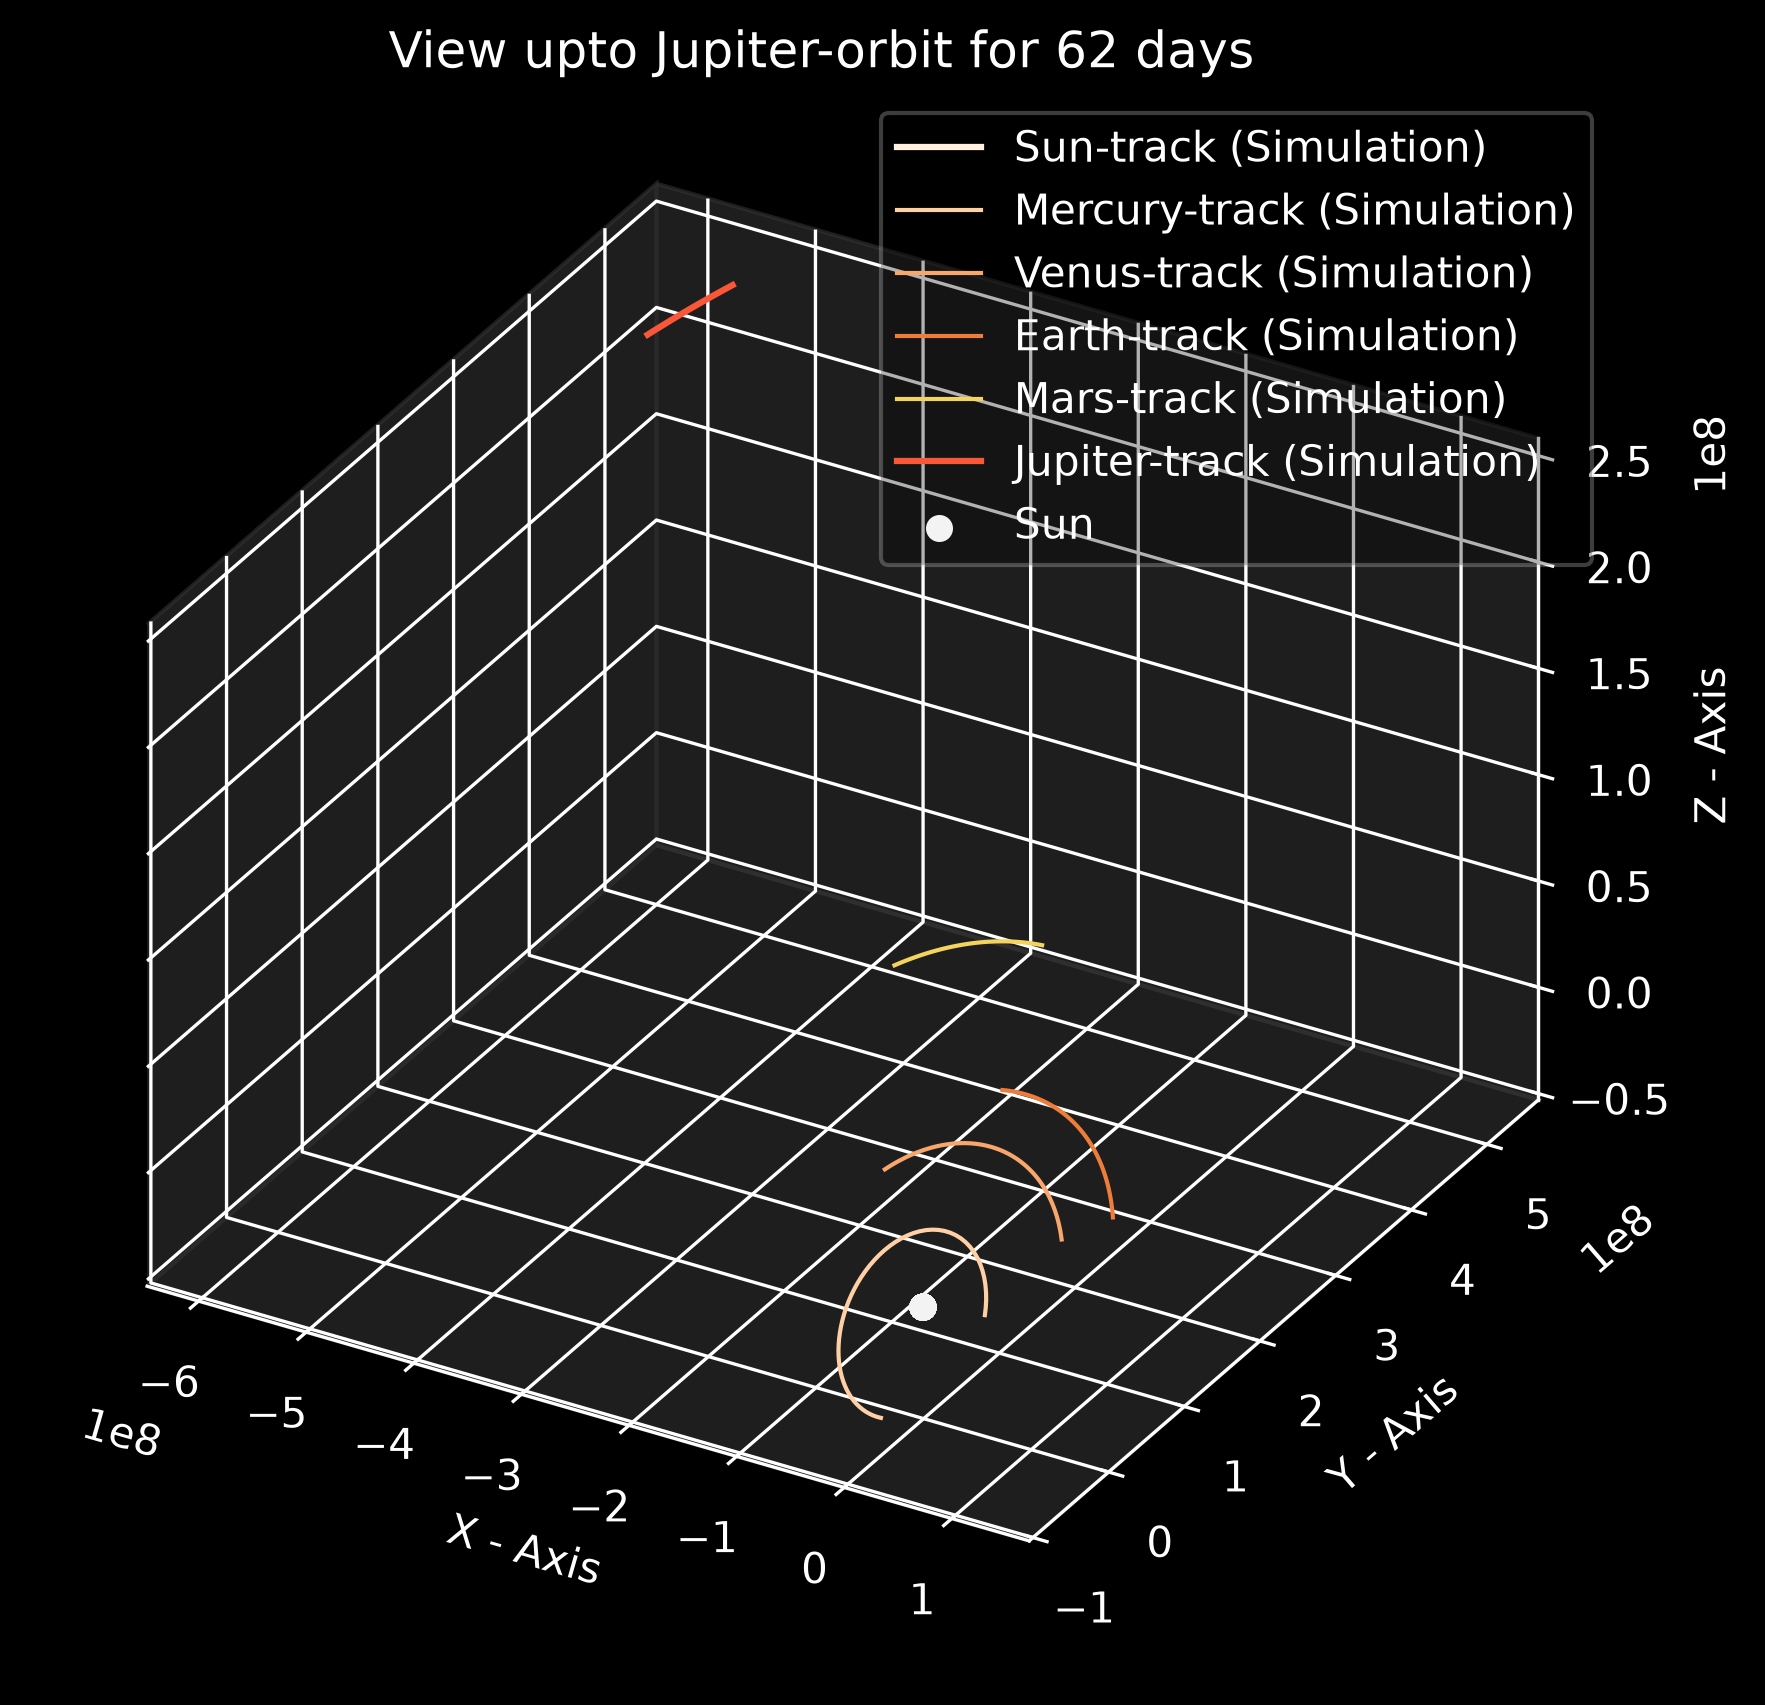

<Figure size 640x480 with 0 Axes>

In [7]:
with plt.style.context("dark_background"):

    fig=plt.figure(figsize=(6,6),dpi=300)
    ax=fig.add_subplot(projection="3d")
    ax.set_title(f"View upto Jupiter-orbit for {days} days")
    ax.set_xlabel("X - Axis")
    ax.set_ylabel("Y - Axis")
    ax.set_zlabel("Z - Axis")
    # Set the background panel colors with a low alpha (e.g., 0.1 for 10% opacity)
    # Format is (Red, Green, Blue, Alpha)
    ax.xaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.yaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.zaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.set_proj_type('ortho')



    ax.plot(sol.y[0],sol.y[1],sol.y[2],color="#fff0df",label="Sun-track (Simulation)")
    ax.plot(sol.y[3],sol.y[4],sol.y[5],lw=1,color="#ffd0a6",label="Mercury-track (Simulation)")

    ax.plot(sol.y[6],sol.y[7],sol.y[8],lw=1,color="#f9a66c",label="Venus-track (Simulation)")
    ax.plot(sol.y[9],sol.y[10],sol.y[11],lw=1,color="#ed7d3a",label="Earth-track (Simulation)")
    ax.plot(sol.y[12],sol.y[13],sol.y[14],lw=1,color="#f4d35e",label="Mars-track (Simulation)")
    ax.plot(sol.y[15],sol.y[16],sol.y[17],lw=1.5,color="#f95738",label="Jupiter-track (Simulation)")
    
    
    ax.scatter(sol.y[0],sol.y[1],sol.y[2],s=30,color="#F3F3F3",label="Sun")

    ax.legend(framealpha=0.3,shadow=False,loc=1)
    plt.tight_layout()

    plt.show()
    plt.savefig('View-upto-Jupiter-orbit.svg')


# $\text{Error-analysis}$

$\text{In this section I will be using the data from the .csv file of the planet Mercury and comparing the error in my simulation wrt the JPL data}$

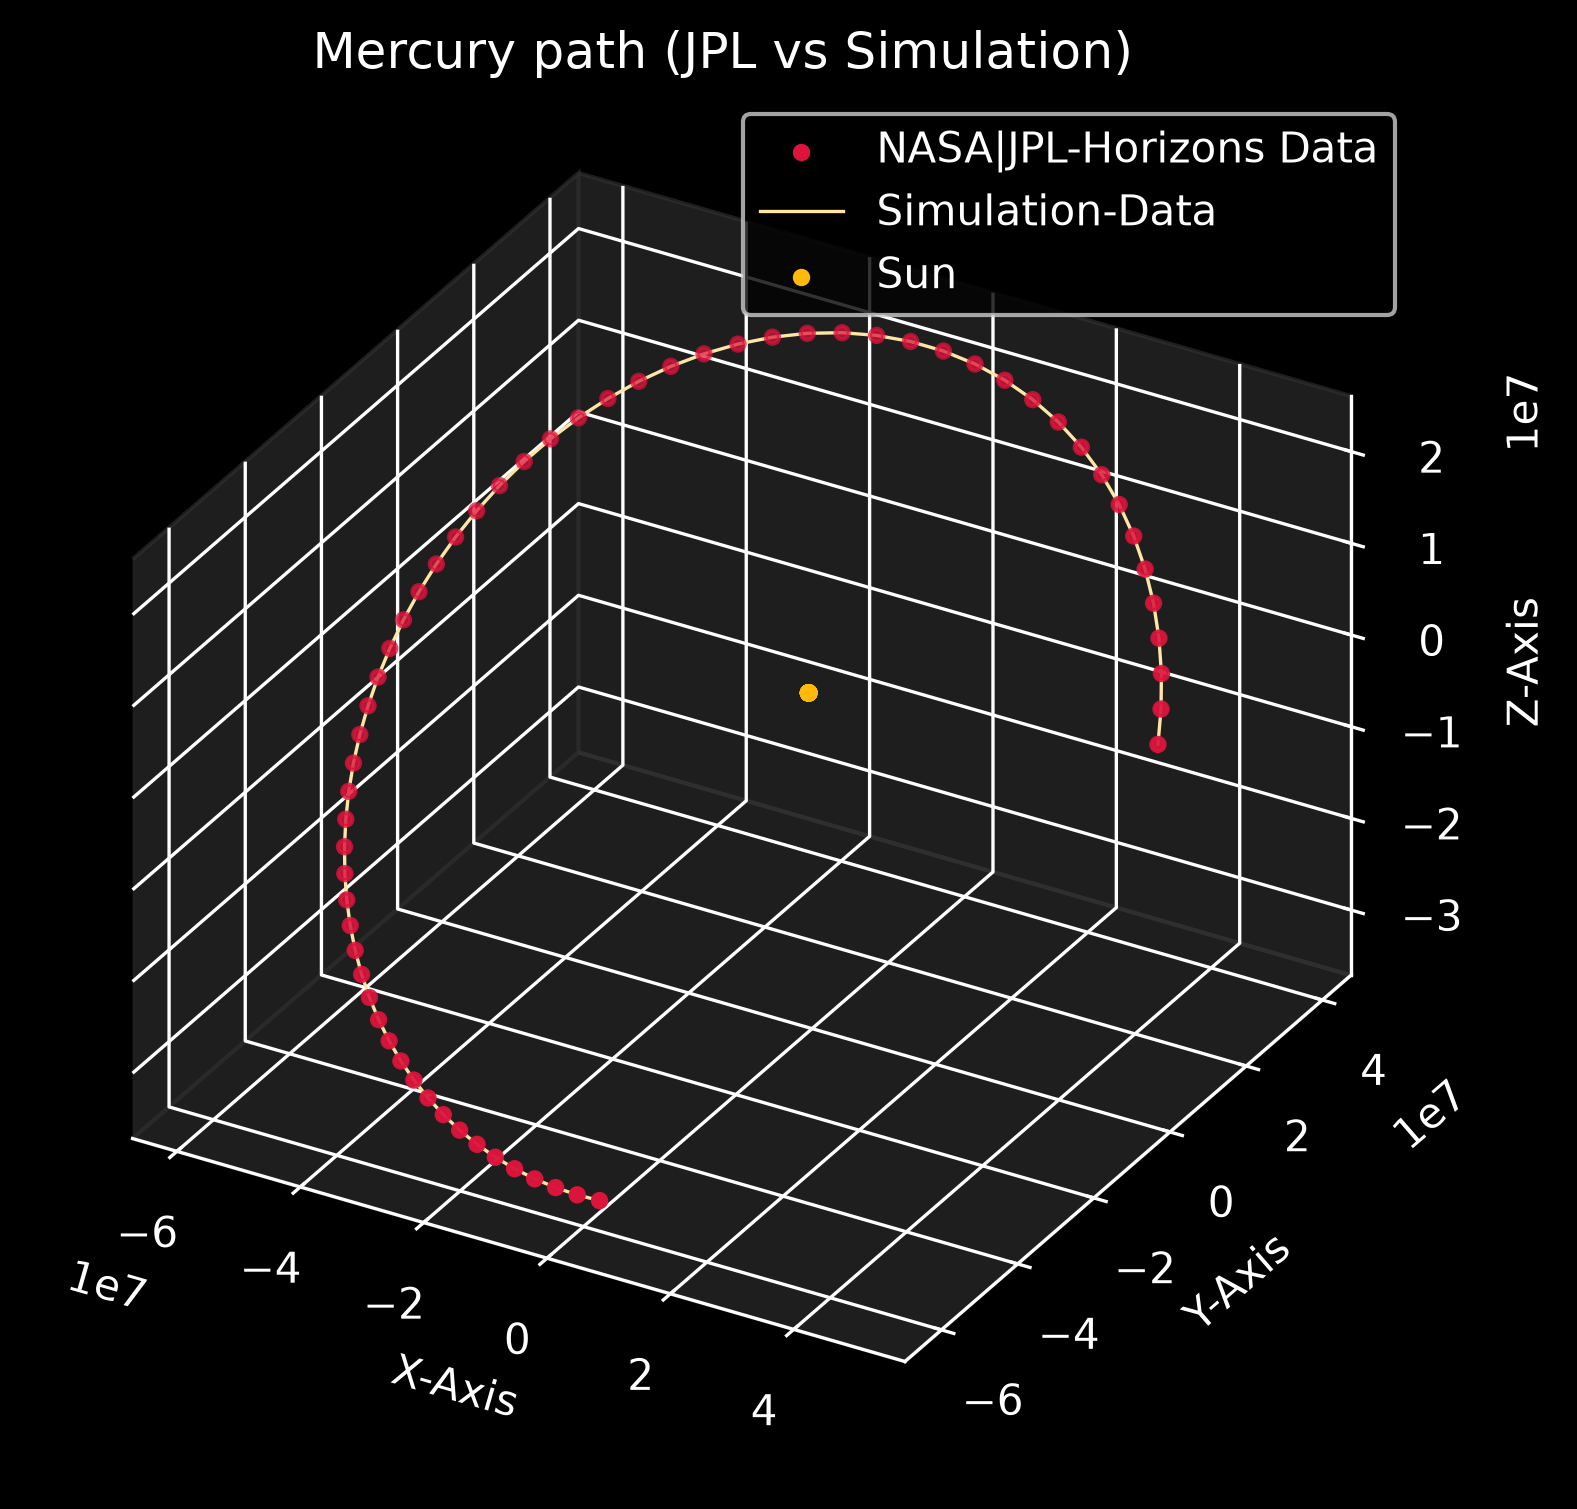

In [8]:
with plt.style.context("dark_background"):
    fig=plt.figure(figsize=(6,6),dpi=300)

    ax=fig.add_subplot(projection="3d")
    ax.set_title("Mercury path (JPL vs Simulation)")
    ax.set_xlabel("X-Axis")
    ax.set_ylabel("Y-Axis")
    ax.set_zlabel("Z-Axis")
    # Set the background panel colors with a low alpha (e.g., 0.1 for 10% opacity)
    # Format is (Red, Green, Blue, Alpha)
    ax.xaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.zaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.yaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.set_proj_type('ortho')

    ax.scatter(JPL_data[0],JPL_data[1],JPL_data[2],s=10,color="crimson",label="NASA|JPL-Horizons Data")
    ax.plot(sol.y[3],sol.y[4],sol.y[5],lw=0.8,color="#ffe6a7",label="Simulation-Data")

    ax.scatter(sol.y[0],sol.y[1],sol.y[2],s=10,color="#ffb90a",label="Sun")
    
    plt.legend()

    plt.show()

# $\text{Error in coordinates:}$

$\text{JPL-Horizon vs Simulation}$

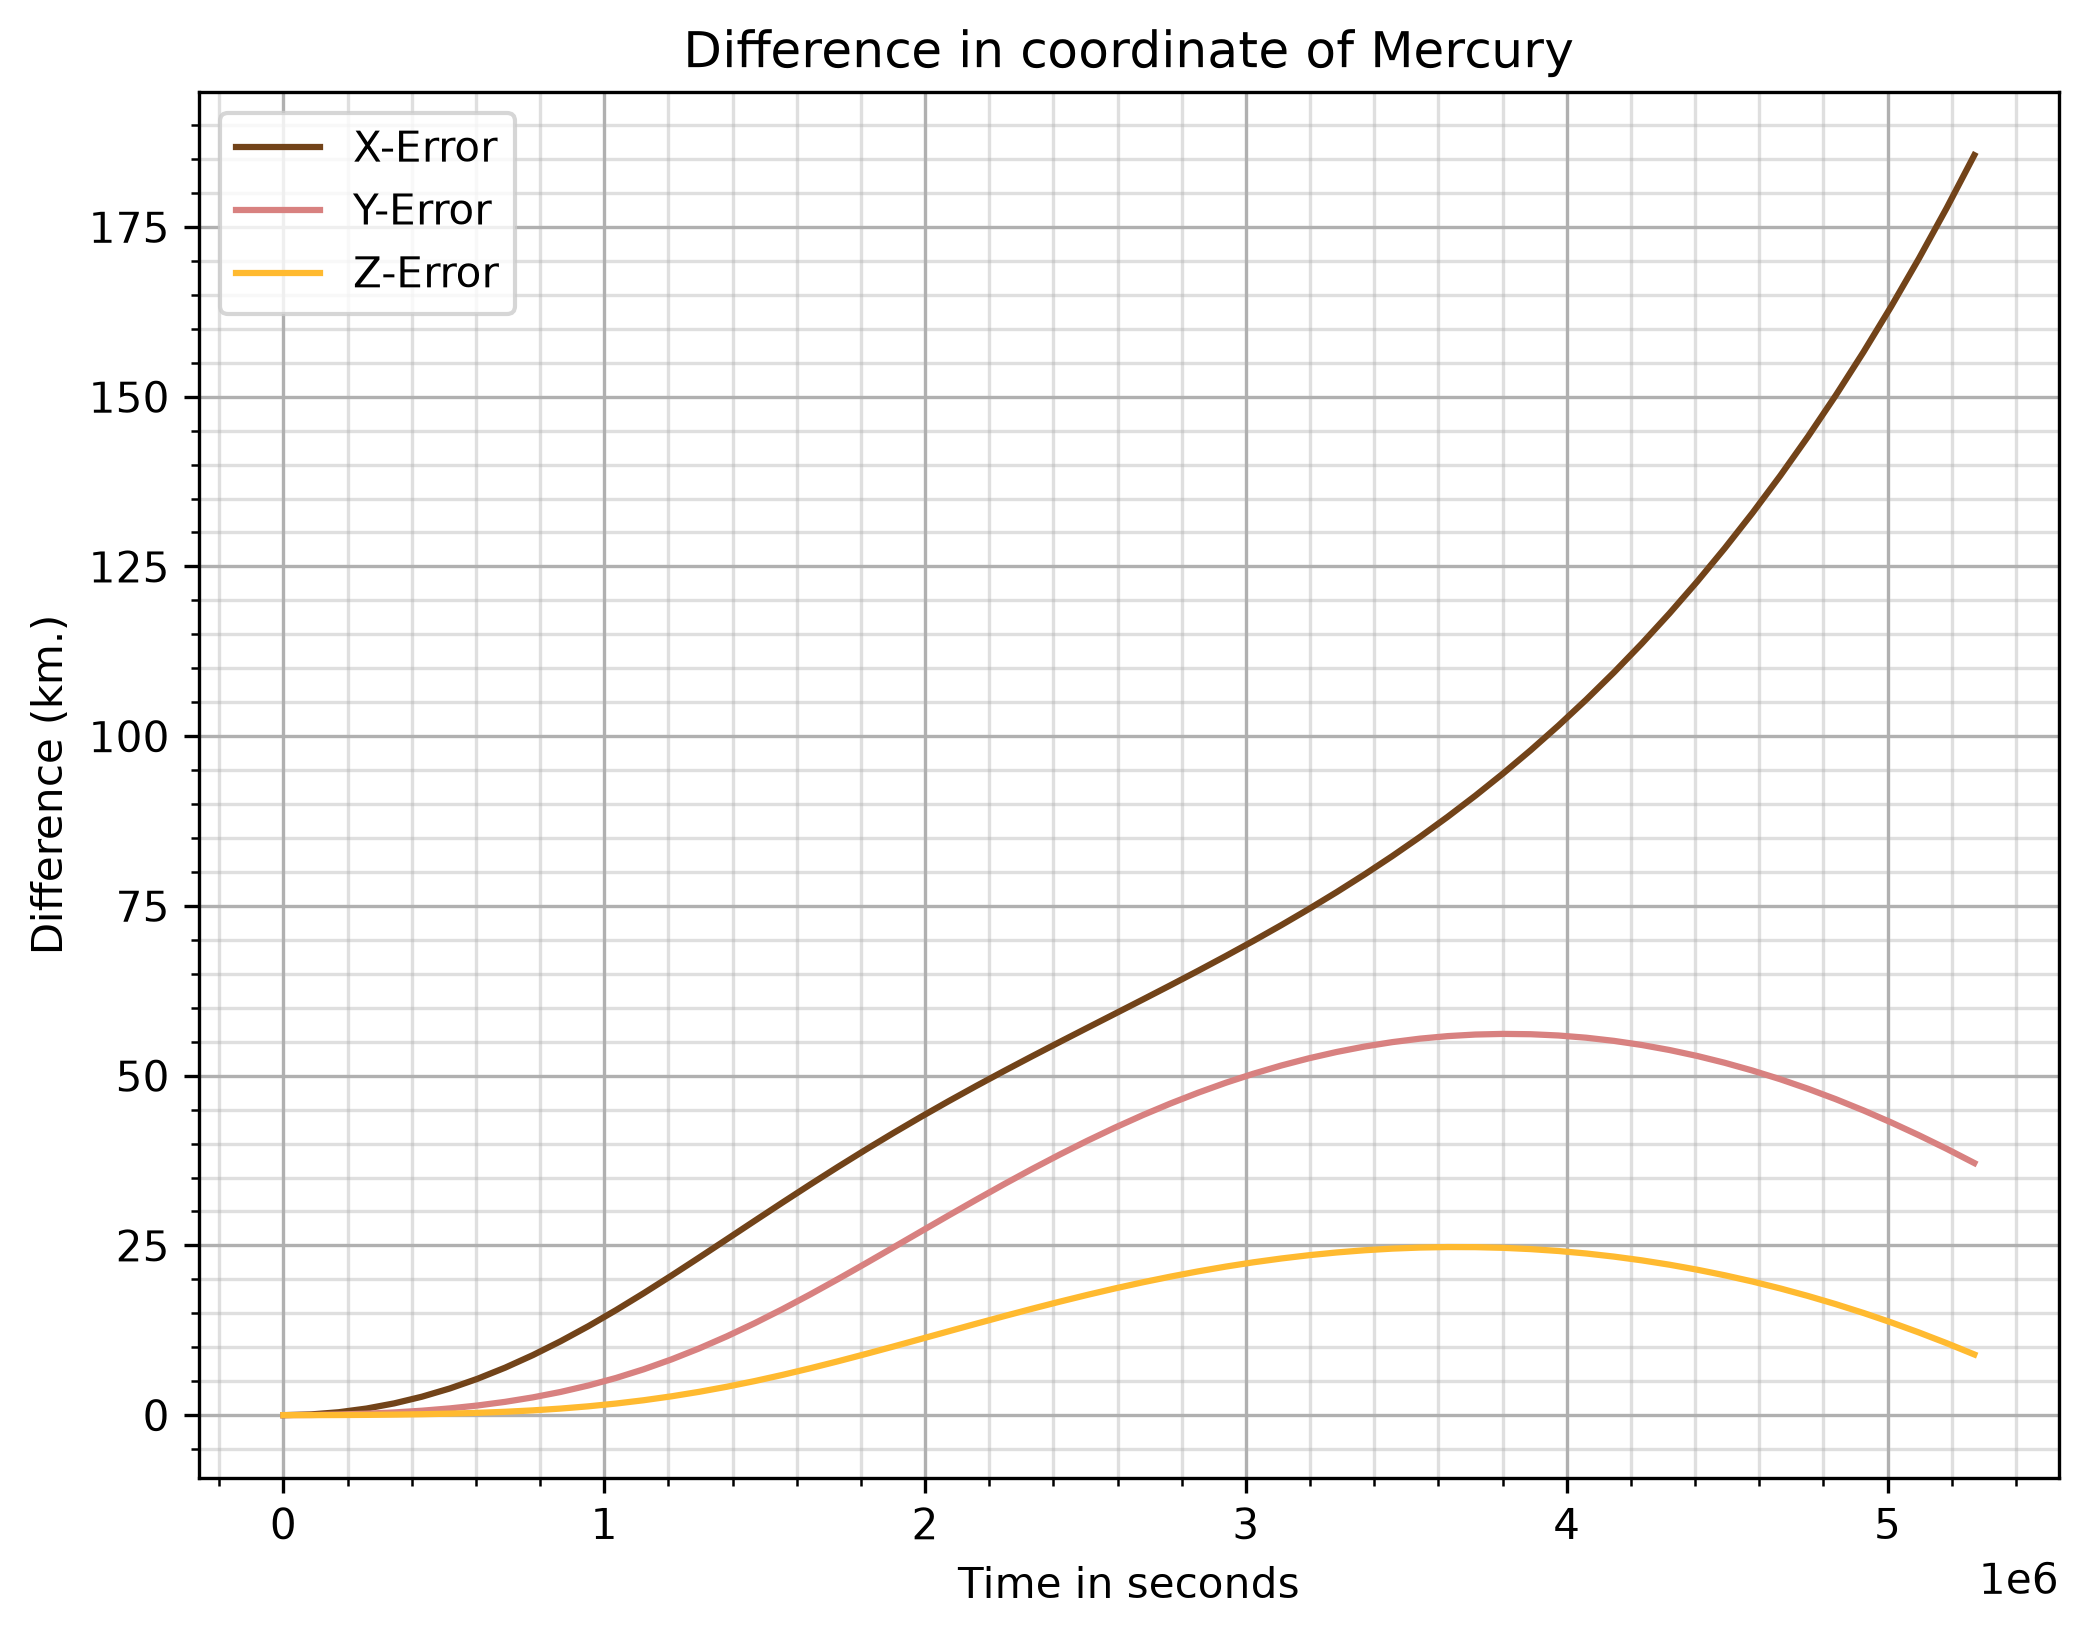

In [9]:
#------------------
# Error-Calculation

ex=(JPL_data[0]-sol.y[3])
ey=(JPL_data[1]-sol.y[4])
ez=(JPL_data[2]-sol.y[5])
#------------------


#--------------
# X-coordinate
plt.figure(figsize=(8,6),dpi=300)
plt.plot(t_eval,ex,color="#724319",label="X-Error")
#--------------



#--------------
# Y-coordinate

plt.plot(t_eval,ey,color="#d88180",label="Y-Error")
#--------------


#--------------
# Z-coordinate

plt.plot(t_eval,ez,color="#ffba30",label="Z-Error")
#--------------


#--------------
# Styling: 

plt.minorticks_on()
plt.grid(which="minor",alpha=0.4)
plt.grid(which="major")
plt.xlabel("Time in seconds")
plt.ylabel("Difference (km.)")
plt.title("Difference in coordinate of Mercury")
plt.legend()
#--------------


#--------------
# Plotting

plt.show()
#--------------